# Hands-on: change the numbers

This notebook lets you change a number, run the cell, and see what happens. All the code is already written. It takes about 15 minutes and does not need `make`.

Each experiment has one number at the top of its cell, marked with a comment. Change it, run the cell (Shift + Enter), and read the output. Run it as many times as you like.

Run this setup cell once. You don't need to read it.

In [1]:
import sys
from math import comb

import matplotlib.pyplot as plt
import numpy as np

sys.path.append("../../src")
from hamiltonians import coupled_modes, hubbard_chain
from utils import ground_state, sample_order, subspace_energy, weight_order

plt.style.use("../../figures.mplstyle")

H_vib, labels_vib = coupled_modes(n_modes=3, n_levels=8)
E0_vib, c0_vib = ground_state(H_vib)
order_vib = weight_order(c0_vib)
sizes_vib = np.unique(np.geomspace(1, len(H_vib) - 1, 40).astype(int))
curve_vib = [subspace_energy(H_vib, order_vib[:k]) - E0_vib for k in sizes_vib]


def check(answer, correct, tol=0):
    if answer is None:
        print("Put your answer in first")
    elif abs(answer - correct) <= tol:
        print(f"Got it, the answer is {correct}")
    elif answer < correct:
        print("Too low, try a bigger number")
    else:
        print("Too high, try a smaller number")


print("Ready")

Ready


## 1. How big does the matrix get?

A chain with `n_sites` sites, half filled with electrons, has this many configurations, and storing its full matrix takes 8 bytes per entry. A typical laptop has about 16 GB of memory.

Try 6, then 8, then keep going.

In [2]:
n_sites = 6  # change this

n_configs = comb(n_sites, n_sites // 2) ** 2
memory_gb = 8 * n_configs**2 / 1e9

print(f"{n_sites} sites: {n_configs:,} configurations")
print(f"Full matrix: {memory_gb:,.3g} GB")
print("Fits on a 16 GB laptop" if memory_gb < 16 else "Does not fit on a 16 GB laptop")

6 sites: 400 configurations
Full matrix: 0.00128 GB
Fits on a 16 GB laptop


What is the smallest number of sites whose matrix does not fit?

In [3]:
my_answer = None  # change this

check(my_answer, 10)

Put your answer in first


Going from 9 sites to 10 takes you from 2 GB to 32 GB. A real molecule has far more than 10 orbitals, which is why nobody builds the full matrix and why the rest of this project is about keeping only part of it.

## 2. How hard do the electrons repel?

`U` is how much energy it costs to put two electrons on the same site. The cell finds the exact answer for a 6-site chain and tells you which configuration matters most, and how many configurations it takes to hold 99% of the weight.

Try `U` = 0, 2, 8 and 20.

Most important configuration: up 010101   down 101010, 16.3% of the weight
Configurations needed for 99% of the weight: 103 of 400


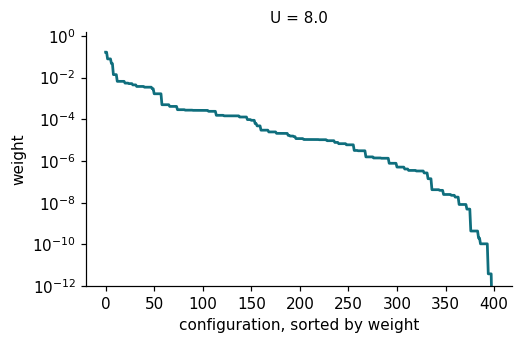

In [4]:
U = 8.0  # change this

H, labels = hubbard_chain(6, 3, 3, U=U)
E0, c0 = ground_state(H)
w = np.sort(c0**2)[::-1]
up, down = labels[weight_order(c0)[0]]

print(f"Most important configuration: up {up:06b}   down {down:06b}, {w[0]:.1%} of the weight")
print(f"Configurations needed for 99% of the weight: {np.searchsorted(np.cumsum(w), 0.99) + 1} of {len(w)}")

fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(w, c="#0f6e7d")
ax.set_ylim(1e-12, 1.5)
ax.set_xlabel("configuration, sorted by weight")
ax.set_ylabel("weight")
ax.set_title(f"U = {U}")
plt.show()

As `U` grows, the 99% count should drop from almost 300 to under 50. Strong repulsion pushes the electrons into the alternating pattern `010101` / `101010`, one per site with spins flipping, so fewer configurations matter. When fewer configurations matter, choosing which ones to keep gets easier.

## 3. How many configurations do you need?

Now the vibrational model, with 512 configurations. The cell keeps the `k` most important ones, solves the smaller problem, and tells you how far off the energy is. The red dot is your choice on the full curve. Chemists usually want to be within 1 cm-1, the dashed line.

Keeping 10 of 512 configurations: off by 562.82 cm-1


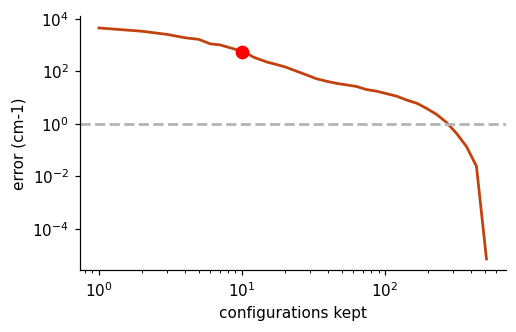

In [5]:
k = 10  # change this, anything from 1 to 512

assert 1 <= k <= 512, "k has to be between 1 and 512"
err = max(subspace_energy(H_vib, order_vib[:k]) - E0_vib, 0.0)  # clip roundoff at k = 512
print(f"Keeping {k} of {len(H_vib)} configurations: off by {err:.2f} cm-1")

fig, ax = plt.subplots(figsize=(5, 3))
ax.loglog(sizes_vib, curve_vib, c="#c2410c")
ax.plot(k, max(err, 1e-6), "o", c="red", ms=8)
ax.axhline(1.0, c=(.7, .7, .7), ls="--")
ax.set_xlabel("configurations kept")
ax.set_ylabel("error (cm-1)")
plt.show()

What is the smallest `k` that gets you under 1 cm-1? Use the cell above to search, then put your answer here. Within 5 counts.

In [6]:
my_answer = None  # change this

check(my_answer, 274, tol=5)

Put your answer in first


Notice that the single most important configuration holds 87% of the weight, but you still need more than half of all 512 to get the energy right. The last bit of accuracy is spread across hundreds of tiny contributions.

## 4. How many measurements?

A quantum computer can't hand us a sorted list like that. It measures a prepared state, and each measurement returns one configuration at random, with probability equal to its weight. Here you choose how many measurements to take on the vibrational model.

Try 1,000, then 100,000, then 1,000,000. Big numbers take a few seconds.

In [7]:
n_shots = 20000  # change this

assert 1 <= n_shots <= 20_000_000, "pick between 1 and 20 million measurements"
found, counts = sample_order(c0_vib, n_shots, np.random.default_rng(0))
err = subspace_energy(H_vib, found) - E0_vib

print(f"{n_shots:,} measurements found {len(found)} of 512 configurations")
print(f"{counts[0]:,} of them were the same configuration")
print(f"Keeping everything found: off by {err:.1f} cm-1")

20,000 measurements found 39 of 512 configurations
17,383 of them were the same configuration
Keeping everything found: off by 54.9 cm-1


How many measurements does it take to find at least 100 different configurations? Anywhere within 25% counts.

In [8]:
my_answer = None  # change this

check(my_answer, 259831, tol=65000)

Put your answer in first


About a quarter of a million measurements to find 100 configurations, when experiment 3 showed we need 274. Even 5 million measurements leaves the error near 4 cm-1. Most measurements return the same configuration over and over, because it holds 87% of the weight.

## What you just found

You found three things, and they are the whole project in miniature: (1) the full matrix becomes impossible to store almost immediately, so we have to keep only part of it, (2) the accuracy lives in a long tail of small contributions, and (3) sampling finds the big contributions quickly and the small ones very slowly. Whether that last point is as bad for real molecules, and whether it is worse for vibrations than for electrons, is what we are testing.